In [1]:
import pandas as pd

red = pd.read_csv("winequality-red.csv", sep=";")
white = pd.read_csv("winequality-white.csv", sep=";")

red["type"] = "red"
white["type"] = "white"
df = pd.concat([red, white], ignore_index=True)

df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,type
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,red
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,red
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,red
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red


In [3]:
print(df.shape)
print("Duplicates:", df.duplicated().sum())
print("Missing values:", df.isna().sum().sum())

df = df.drop_duplicates().reset_index(drop=True)
print("After dropping duplicates:", df.shape)

df["quality"].value_counts().sort_index()

(6497, 13)
Duplicates: 1177
Missing values: 0
After dropping duplicates: (5320, 13)


,count
quality,
3,30
4,206
5,1752
6,2323
7,856
8,148
9,5


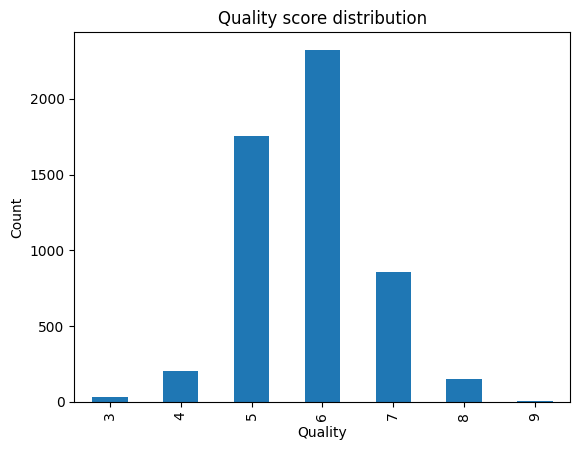

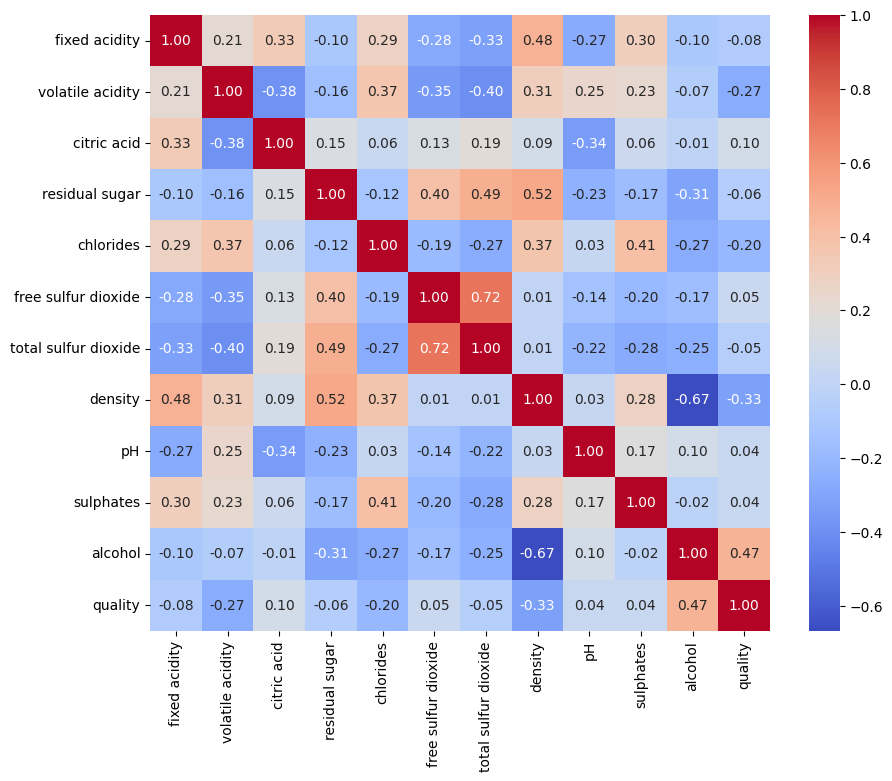

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

df["quality"].value_counts().sort_index().plot(kind="bar")
plt.title("Quality score distribution")
plt.xlabel("Quality"); plt.ylabel("Count")
plt.show()

plt.figure(figsize=(10, 8))
sns.heatmap(df.drop(columns="type").corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.show()

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# turn red/white into a 0/1 column
X = pd.get_dummies(df.drop(columns="quality"), columns=["type"], drop_first=True)
y = df["quality"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

models = {
    "Baseline (predict mean)": DummyRegressor(strategy="mean"),
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=200, random_state=42),
}

for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    mae = mean_absolute_error(y_test, pred)
    rmse = np.sqrt(mean_squared_error(y_test, pred))
    r2 = r2_score(y_test, pred)
    print(f"{name:25s} MAE={mae:.3f}  RMSE={rmse:.3f}  R2={r2:.3f}")

Baseline (predict mean)   MAE=0.694  RMSE=0.868  R2=-0.001
Linear Regression         MAE=0.560  RMSE=0.721  R2=0.309
Random Forest             MAE=0.509  RMSE=0.663  R2=0.415


In [6]:
from sklearn.model_selection import cross_val_score

rf = RandomForestRegressor(n_estimators=200, random_state=42)
scores = cross_val_score(rf, X, y, cv=5, scoring="neg_mean_absolute_error")
print("CV MAE:", -scores.mean(), "+/-", scores.std())

CV MAE: 0.5725639097744362 +/- 0.018756163505404322


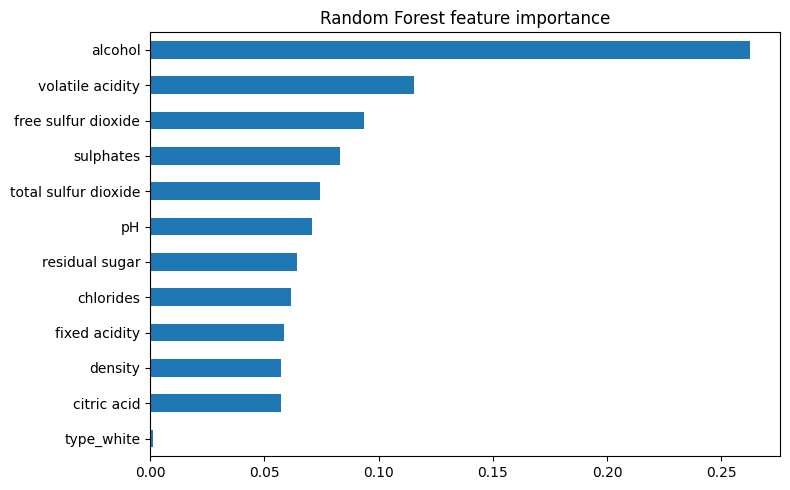

In [7]:
rf.fit(X_train, y_train)
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values()
imp.plot(kind="barh", figsize=(8, 5))
plt.title("Random Forest feature importance")
plt.tight_layout()
plt.savefig("feature_importance.png")
plt.show()

In [8]:
import joblib
joblib.dump(rf, "model.joblib")
print(list(X.columns))   # the exact column order the app must use

['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'type_white']
